# LeetCode #144: Binary Tree Preorder Traversal

https://leetcode.com/problems/binary-tree-preorder-traversal/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Recursive | O(n) | O(h) |
| Iterative with Stack ★ | O(n) | O(h) |
| Morris Traversal | O(n) | O(1) |

## Understanding the Methods
### Brute Force (Recursive)
Visit root, then recurse left, then right. Elegant but uses O(h) call stack space where h is height.

### Optimal: Iterative with Stack ★
Use an explicit stack. Push root, then repeatedly pop a node, add to result, push right child then left child (so left is processed first). O(n) time, O(h) space. Avoids recursion overhead.

### Morris Traversal
O(1) extra space by temporarily modifying the tree structure using threaded binary tree concept. Restores the tree after traversal.

## Solutions
### C#

In [ ]:
// Iterative Stack O(n) time, O(h) space
public class Solution {
    public IList<int> PreorderTraversal(TreeNode root) {
        var result = new List<int>();
        if (root == null) return result;
        var stack = new Stack<TreeNode>();
        stack.Push(root);
        while (stack.Count > 0) {
            var node = stack.Pop();
            result.Add(node.val);
            if (node.right != null) stack.Push(node.right);
            if (node.left != null) stack.Push(node.left);
        }
        return result;
    }
}

### Python

In [ ]:
# Iterative Stack O(n) time, O(h) space
class Solution:
    def preorderTraversal(self, root: 'Optional[TreeNode]') -> list[int]:
        if not root:
            return []
        result, stack = [], [root]
        while stack:
            node = stack.pop()
            result.append(node.val)
            if node.right:
                stack.append(node.right)
            if node.left:
                stack.append(node.left)
        return result

### Go

In [ ]:
// Iterative Stack O(n) time, O(h) space
func preorderTraversal(root *TreeNode) []int {
    if root == nil { return nil }
    result := []int{}
    stack := []*TreeNode{root}
    for len(stack) > 0 {
        node := stack[len(stack)-1]
        stack = stack[:len(stack)-1]
        result = append(result, node.Val)
        if node.Right != nil { stack = append(stack, node.Right) }
        if node.Left != nil { stack = append(stack, node.Left) }
    }
    return result
}

### Rust

In [ ]:
// Iterative Stack O(n) time, O(h) space
use std::rc::Rc;
use std::cell::RefCell;

impl Solution {
    pub fn preorder_traversal(root: Option<Rc<RefCell<TreeNode>>>) -> Vec<i32> {
        let mut result = Vec::new();
        let mut stack = Vec::new();
        if let Some(r) = root { stack.push(r); }
        while let Some(node) = stack.pop() {
            let n = node.borrow();
            result.push(n.val);
            if let Some(right) = n.right.clone() { stack.push(right); }
            if let Some(left) = n.left.clone() { stack.push(left); }
        }
        result
    }
}

## Example Scenarios

### 1. Common Case — Right-Leaning
**Input:** `root=[1,null,2,3]`

Preorder visits **root, left, right**. Visit $1$, its (empty) left, then subtree $2$ whose left child $3$ comes before returning. Output $[1,2,3]$.

### 2. Slightly Complex — Full Small Tree
**Input:** `root=[1,2,3,4,5]`

Visit root $1$, descend the left subtree ($2$ then its children $4,5$), then the right subtree $3$. Output $[1,2,4,5,3]$.

### 3. Edge Case: Time Factor — Empty Tree
**Input:** `root=[]`

No nodes to visit; the traversal returns immediately. Output $[\,]$.

### 4. Edge Case: Space Factor — Single Node
**Input:** `root=[1]`

Only the root exists; it is visited first and last. Output $[1]$.

### 5. Almost-Impossible but Plausible — Left-Skewed Chain
**Input:** `root=[1,2,null,3,null,4,null,5]`

A degenerate chain of left children (height $=n$). Preorder visits each node top-down: $[1,2,3,4,5]$; recursion depth reaches $O(n)$.


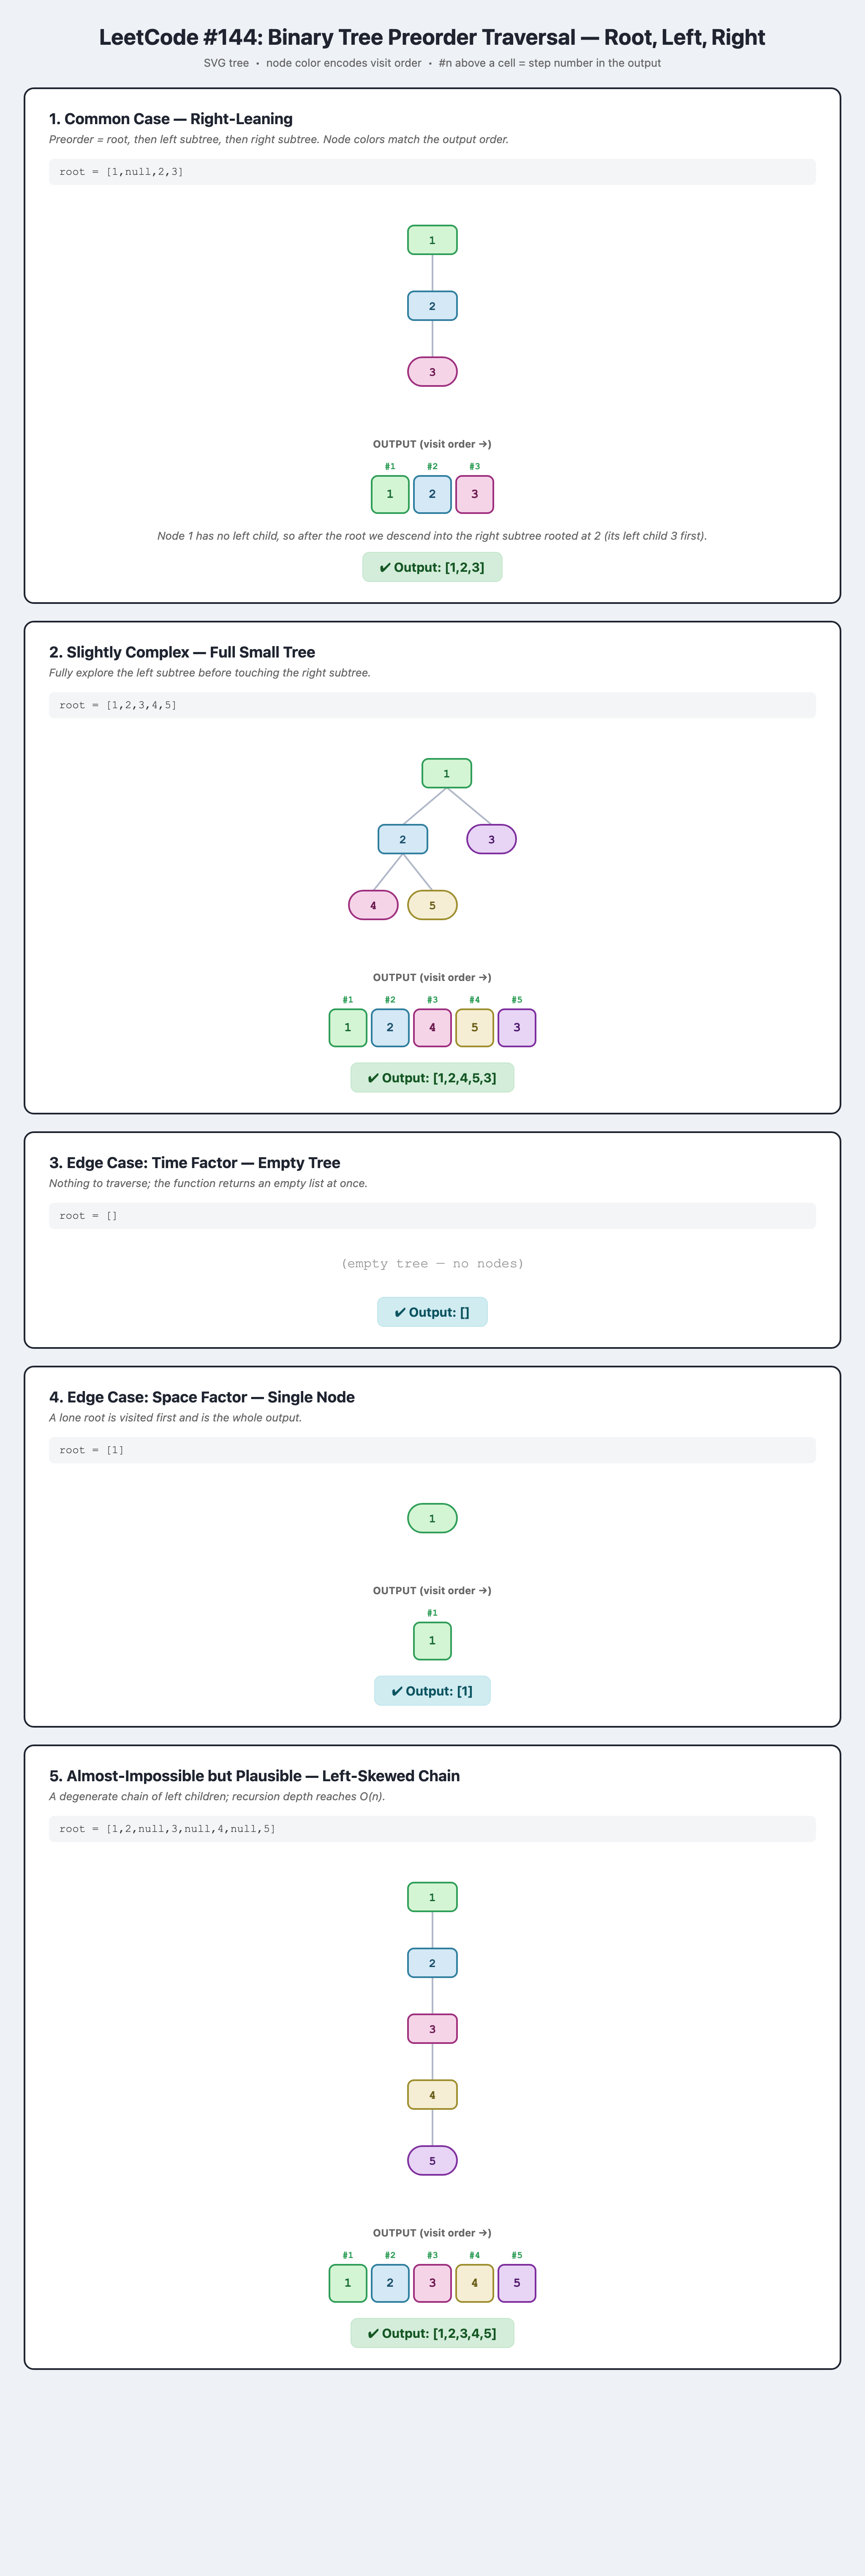